# QC0426 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep

from hera.analysis import GateCalibration, field_invB

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205
from drivers.async_station import async_station

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260620-QC0426'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.019 A
Voltage:             : -0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')  # <-- verify address
print(heater.sample_temperature())
print(heater.vaporizer_temperature())

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.41s
1.153
0.0


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.08s


Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400 = Keithley_2400('k_2400', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400.mode.set('VOLT')
k_2400.volt.set(0)
k_2400.rangei.set(1e-6)
k_2400.rangev.set(21)
k_2400.volt.step = 0.005
k_2400.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [7]:
k_2410 = Keithley_2400('k_2410', 'GPIB0::25::INSTR')  # <-- verify address — Si-gate Keithley
k_2410.mode.set('VOLT')
k_2410.volt.set(0)
k_2410.rangei.set(1e-6)
k_2410.rangev.set(21)
k_2410.volt.step = 0.005
k_2410.volt.inter_delay = 0.01  # Si gate dV/dt pacing - dielectric safety
k_2410.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2410 (serial:1293333, firmware:C30   Mar 17 2006 09:29:29/A02  /J/J) in 0.03s


## DC205 (top gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — top-gate DC205
dc205.ramp_rate = 2  # V/s

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). The dc205_volt
# wrapper is generic; the k_* role map is device-specific. Each value
# `# <-- validate`.

# Sweepable top-gate parameter — appears in the data as column 'DC_bias'.
def dcbias(vg):
    dc205.ramp_voltage(vg)

dc205_volt = qcodes.Parameter('DC_bias', unit='V', set_cmd=dcbias)

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = dc205_volt   # top gate <- DC205 (fast axis is dc205_volt, NOT k_tg.volt)   # <-- validate
k_bg = k_2400       # back gate <- Keithley 2400                                     # <-- validate
k_si = k_2410       # Si gate   <- Keithley 2410                                     # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (dc205 / k_2400 / k_2410); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -6.0, +7.0    # top gate (dc205_volt), V    # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400), V        # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (k_2410), V          # <-- validate
dc205_volt.vals = validators.Numbers(TG_MIN, TG_MAX)
dc205.voltage.vals = validators.Numbers(TG_MIN, TG_MAX)  # instrument-level: direct dc205 calls bypass dc205_volt
k_2400.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
k_2410.volt.vals = validators.Numbers(SI_MIN, SI_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 310.0  # K    # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text.
meas_config = {
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4 (Rxx)",  # <-- validate
    "sr2": "B4-B5 (Rxx)",  # <-- validate
    "sr3": "T5-B6 (Rxy, Hall)",  # <-- validate
    "bias_resistor": 100e6,
    "bias_voltage": sr1.amplitude(),
    "lockin_freq": sr1.frequency(),
    "sr0_sens": sr0.sensitivity(),
    "sr1_sens": sr1.sensitivity(),
    "sr2_sens": sr2.sensitivity(),
    "sr3_sens": sr3.sensitivity(),
    "sample_temperature:": heater.sample_temperature(),  # key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": k_2410.volt(),
    "comments": "<SET PER RUN>",
}

## QSwitch (contact mux) — LIVE

Contact-mux bring-up and the line/breakout maps are device-specific — from the
device card's Contact map section. `qsw.reset()` is **always forbidden** — it
opens the Si standing closures and drops the Si gate.

In [14]:
from drivers.QSwitch import QSwitch
from drivers.contact_mux import ContactMux

qsw = QSwitch('qswitch', 'ASRL4::INSTR')  # <-- verify address — QSwitch

# Contact label -> QSwitch line. Si standing-closure lines are EXCLUDED.
LINES = {  # <-- validate (from card contact map)
    "T1": 1,  "T2": 3,  "T3": 4,  "T4": 6,  "T5": 7,  "T6": 12, "T7": 13,
    "B1": 8,  "B2": 17, "B3": 23, "B4": 22, "B5": 20, "B6": 19, "B7": 18, "B8": 15,
}
# Instrument port -> front-panel BNC tap.
BREAKOUTS = {  # <-- validate (from card instrument taps)
    "source": 7, "drain": 8,
    "sr1+": 1, "sr1-": 2, "sr2+": 3, "sr2-": 4, "sr3+": 5, "sr3-": 6,
}
SETTLE_S = 4  # <-- validate (calibrated relay settle)

mux = ContactMux(qsw, lines=LINES, breakouts=BREAKOUTS, settle_s=SETTLE_S)
# qsw.reset() ALWAYS FORBIDDEN — drops the Si gate (standing closures).

Connected to: Quantum Machines QSwitch (serial:37, firmware:2.0) in 0.05s


# HERA — session start (2026-06-20) · QC0426

## HERA — E1 engaged · kernel-binding probe

Grant received ("go for autonomy"), recorded in `session_notes.md`. First E1 execute is a **read-only** namespace probe — no instrument writes, no sweeps. It confirms (a) this execute is bound to the operator's instrument-carrying kernel — live reads must match bring-up (~0 T, ~1.15 K, all gates at 0 V), not a fresh kernel; and (b) the SAFETIES validators are live in *this* kernel (gate B holds for the executing process). ~5 s.


In [15]:
# E1 kernel-binding probe — READ-ONLY. No instrument writes, no sweeps.
names = ['magnet','heater','sr0','sr1','sr2','sr3','k_2400','k_2410',
         'dc205','dc205_volt','qsw','mux','meas_config']
print("bound names :", {n: (n in globals()) for n in names})

# live reads — must match bring-up if bound to the right kernel
print("magnet.field()       =", round(magnet.field(), 4), "T   (expect ~0)")
print("sample_temperature() =", round(heater.sample_temperature(), 3), "K  (expect ~1.15)")
print("k_2410.volt() [Si]   =", k_2410.volt(), "V   (expect 0)")
print("k_2400.volt() [BG]   =", k_2400.volt(), "V   (expect 0)")
print("dc205.voltage() [TG] =", dc205.voltage(), "V   (expect 0)")

# SAFETIES validators live in THIS kernel
print("dc205_volt.vals  =", dc205_volt.vals)
print("k_2400.volt.vals =", k_2400.volt.vals)
print("k_2410.volt.vals =", k_2410.volt.vals)
print("magnet.field.vals=", magnet.field.vals)

# QSwitch / mux bound (no reset, no select — confirm object + settle only)
print("mux.settle_s =", mux.settle_s, "| qsw serial =", qsw.IDN().get('serial', '?'))


bound names : {'magnet': True, 'heater': True, 'sr0': True, 'sr1': True, 'sr2': True, 'sr3': True, 'k_2400': True, 'k_2410': True, 'dc205': True, 'dc205_volt': True, 'qsw': True, 'mux': True, 'meas_config': True}
magnet.field()       = 0.0027 T   (expect ~0)
sample_temperature() = 1.153 K  (expect ~1.15)
k_2410.volt() [Si]   = 0.0 V   (expect 0)
k_2400.volt() [BG]   = 0.0 V   (expect 0)
dc205.voltage() [TG] = 0.0 V   (expect 0)
dc205_volt.vals  = <Numbers -6.0<=v<=7.0>
k_2400.volt.vals = <Numbers -4.5<=v<=4.5>
k_2410.volt.vals = <Numbers -50.0<=v<=50.0>
magnet.field.vals= <Numbers -8.0<=v<=8.0>
mux.settle_s = 4 | qsw serial = 37


## HERA — Gate C · contact-config liveness (first-session branch)

No designated references (first session on this device for HERA), so this is judged on its own terms: **select the provided contact configuration** and confirm every channel is alive at the current operating point (gates 0 V, B ≈ 0). Routing is read back from hardware; the Si standing closures (QSwitch lines 16/11) are *excluded* from the mux's managed set, so the select must leave them closed — verified explicitly below. The comprehensive gate-response sweep is the next step (the 0 T gate map / CNP calibration); this is the cheap predecessor that protects it. ~10 s (relay settle 4 s).

Stop-and-report if any channel reads railed (pinned at full-scale sensitivity) or dead (zero current / zero voltage), or if a Si closure is missing.


In [16]:
# Gate C — contact-config liveness (first-session branch; no designated refs).
from drivers.QSwitch import channel_list_to_state

# preconditions (state this cell assumes but does not set)
assert abs(magnet.field()) < 0.05, f"field not ~0: {magnet.field()}"
assert heater.sample_temperature() < 2.0, f"sample T high: {heater.sample_temperature()}"
assert k_2410.volt() == 0 and k_2400.volt() == 0 and dc205.voltage() == 0, "gates not at 0 V"

# route the provided contact configuration (device card)
mux.select({"source": "T2", "drain": "B7",
            "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5",
            "sr3+": "T5", "sr3-": "B6"})

frag = mux.mc_fragment()
print("routing  :", frag["qswitch_routing"])
raw = frag["qswitch_state"]
st = channel_list_to_state(raw) if isinstance(raw, str) else list(raw)
si = sorted({ln for (ln, tap) in st if ln in (11, 16)})
print("Si standing-closure lines present:", si, " (expect [11, 16])")

# liveness: lock-in reads at the current (unknown-density) operating point
ib = sr1.amplitude() / meas_config["bias_resistor"]
print(f"\nI_bias = {ib*1e9:.3f} nA  (sr1.amplitude={sr1.amplitude()} V / {meas_config['bias_resistor']:.0e} ohm)")
isr0 = sr0.X() / meas_config["sr0_gain"]          # drain current (gain-divided)
print(f"sr0 (drain current): I = {isr0*1e9:+.3f} nA   X={sr0.X():+.3e} sens={sr0.sensitivity()}")
for ch in ['sr1', 'sr2', 'sr3']:
    s = globals()[ch]
    V = s.X()
    R = V / isr0 if isr0 != 0 else float('nan')
    print(f"{ch}: X={V:+.3e} V  Y={s.Y():+.3e}  R={s.R():.3e}  -> R4t~{R:+.0f} ohm  sens={s.sensitivity()}")


routing  : {'source': 'T2', 'drain': 'B7', 'sr1+': 'T3', 'sr1-': 'T4', 'sr2+': 'B4', 'sr2-': 'B5', 'sr3+': 'T5', 'sr3-': 'B6'}
Si standing-closure lines present: [11, 16]  (expect [11, 16])

I_bias = 5.000 nA  (sr1.amplitude=0.5 V / 1e+08 ohm)
sr0 (drain current): I = +4.992 nA   X=-4.992e-03 sens=0.05
sr1: X=+7.140e-06 V  Y=-3.502e-07  R=7.152e-06  -> R4t~+1431 ohm  sens=2e-05
sr2: X=+6.194e-06 V  Y=-3.902e-07  R=6.208e-06  -> R4t~+1241 ohm  sens=2e-05


sr3: X=+1.341e-06 V  Y=-2.608e-08  R=1.341e-06  -> R4t~+269 ohm  sens=0.0001


## HERA — Step 1 · 0 T gate map (CNP / (n,D) calibration source)

First real measurement of the investigation ladder (`trilayer-stacking-fs-count` Step 1 → `cnp-and-dline-calibration`). Nothing on disk to mine (strict isolation), so we measure the CNP fresh. At gates = 0 the device read ~1.3 kΩ (metallic) → CNP is offset; its (V_tg, V_bg) intercept is **unknown**, so this first map sweeps the **full validated gate ranges** to guarantee the CNP ridge is captured.

**Design.** BG (graphite, `k_bg`) **slow** × TG (DC205, `dc205_volt`/`DC_bias`) **fast** — TG is the fast gate on this rig (device card). `bg ∈ [−4.5, 4.5]`×37 (ΔBG 0.25 V), `tg ∈ [−6, 7]`×105 (ΔTG 0.125 V). B = 0, Si = 0 V (contact-doping gate, screened from channel). `fast_delay = 1.2 s` (= 4τ floor, τ = 0.3 s / 24 dB/oct), `slow_delay = 3 s`. Follow: `sr0–sr3 .X` (raw; gains in meas_config) + `k_2400/k_2410 .curr` (BG/Si leakage). **No per-point Lakeshore poll** (rig-card Grafana/VISA contention quirk) — T read at start/end.

**Coverage trade.** Geometry prior gives CNP slope ≈ −1.3, so the ridge traverses ~11.7 V of TG diagonally across the BG range — extreme rows may clip at the TG window edges and get dropped from the line fit (recipe guard). Full range is the right *first* map; a re-centered/denser map follows once the intercept is known.

**Wall-clock ≈ 1.6 h** (per-pt ≈ fast_delay + ~0.15 s concurrent reads; row turnaround ≈ DC205 reset 6.5 s + slow_delay). **Checkpoint at row ~10 (~26 min)** via backgrounded `hera-watch`: (a) ridge visible & traversing within the TG window → continue; (b) ridge pinned at TG edge every row → intercept out of frame, abort & re-center (~26 min sunk); (c) BG/Si leakage approaching 1 nA → abort immediately. First run → `data/0`.


start: T=1.153 K, B=0.0027 T, Si=0.0 V


at start: TG=-6.000 V, BG=-4.500 V | megasweep 37x105 = 3885 pts
2026-06-20 20:56:06,280 [INFO] Starting megasweep with ID 0


2026-06-20 20:56:06,280 [INFO] Minimum duration 1h 19m 33s


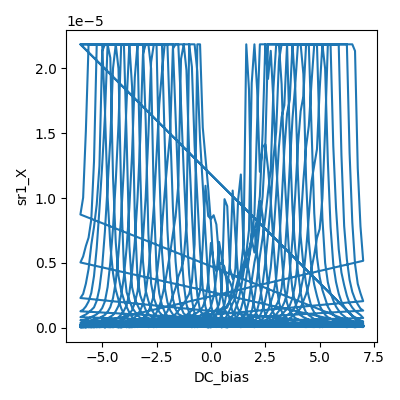

2026-06-20 22:31:58,196 [INFO] Completed in 1h 35m 51s


2026-06-20 22:31:58,197 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260620-QC0426\data\0\data.tsv.gz


DONE run id=0 | T start/end = 1.153/1.153 K | gates parked to 0 V


In [17]:
import numpy as np, time

# ---- preconditions (state assumed but not set by this cell) ----
assert abs(magnet.field()) < 0.05, f"field not ~0: {magnet.field()}"
assert heater.sample_temperature() < 2.0, f"sample T high: {heater.sample_temperature()}"
assert k_2410.volt() == 0, f"Si gate not at contact-doping point 0 V: {k_2410.volt()}"
T0 = heater.sample_temperature()
print(f"start: T={T0:.3f} K, B={magnet.field():.4f} T, Si={k_2410.volt()} V")

# ---- map design: BG slow x TG(DC205) fast, full validated ranges, B=0, Si=0 ----
bg_vec = np.linspace(-4.5, 4.5, 37)     # slow: graphite back gate (k_bg = k_2400), dBG=0.25 V
tg_vec = np.linspace(-6.0, 7.0, 105)    # fast: top gate (dc205_volt -> column DC_bias), dTG=0.125 V
SLOW_DELAY, FAST_DELAY = 3.0, 1.2       # fast_delay = 4*tau floor (tau=0.3s, 24 dB/oct; device card)

# ---- station (fresh -> no inherited comments) ----
meas_config["comments"] = ("gatemap CNP-find | QC0426 3LGr | B=0, Si=0V, base T | "
                           "BG[-4.5,4.5]x37 slow, TG/DC_bias[-6,7]x105 fast | "
                           "src T2 / drain B7 / sr1 T3-T4 / sr2 B4-B5 / sr3 T5-B6(Hall)")
meas_config["sample_temperature:"] = T0
meas_config["Si (V)"] = k_2410.volt()
s = async_station(meas_config)
s.add_comment('gatemap')
s.add_comment('cnp-and-dline-calibration: source map for CNP-line slope (c_bg/c_tg) + (n,D) offset')

# follow params: 4 lock-in X raw (gains in meas_config) + BG/Si leakage. NO LS335 per-point.
s.fp(sr0.X).fp(sr1.X).fp(sr2.X).fp(sr3.X).fp(k_2400.curr).fp(k_2410.curr)
s.plot(dc205_volt, sr1.X)   # live fast-axis Rxx trace (plot.png = monitor, re-form from TSV for analysis)

# ---- ramp gates to start, settle ----
dc205_volt(tg_vec[0]); k_bg.volt(bg_vec[0])
time.sleep(5)
print(f"at start: TG={dc205.voltage():.3f} V, BG={k_2400.volt():.3f} V | "
      f"megasweep {len(bg_vec)}x{len(tg_vec)} = {len(bg_vec)*len(tg_vec)} pts")

res = s.megasweep(k_bg.volt, bg_vec, dc205_volt, tg_vec, slow_delay=SLOW_DELAY, fast_delay=FAST_DELAY)

# ---- park gates + end state ----
dc205_volt(0.0); k_bg.volt(0.0)
T1 = heater.sample_temperature()
print(f"DONE run id={res.id} | T start/end = {T0:.3f}/{T1:.3f} K | gates parked to 0 V")


## HERA — Step 3 · SdH spot check, HOLE side (n = −3.4e12, D = 0)

`trilayer-stacking-fs-count` Step 2→3. **Feasibility (Step 2):** F_L = (h/4e)·n = 35.2 T at |n|=3.4e12 (the fastest possible tone, single 4-fold pocket). Nyquist it: Δ(1/B) = 1/(3·F_L) = 0.00948 T⁻¹. Window B = 0.1→2.0 T uniform **in 1/B** (`field_invB`, densest in B at low field → captures the onset for free), 1/B span 9.5 T⁻¹ → N = 1001, ~334 periods of an F_L tone, FFT freq resolution Δf ≈ 0.105 T. This Δ(1/B) carries to the fan (Step 4).

**Why hole first:** the ML/BL pockets are more balanced on the hole side at equal |n| (a prior, not a rule — electron side gets its own spot check next). n = 3.4e12 sits at the Onsager-model validity ceiling (3.5e12), so the overlay stays available for the read. The FS-count combinatorics (one tone at F_L = ABC; a pair summing to F_L = ABA) is read per Rxx channel (sr1 T3-T4, sr2 B4-B5) from the 1/B FFT.

**Acquisition:** high-|n| metallic bias **2 V / 20 nA** (Rxx ~tens of Ω); voltage channels **autorange** at the operating point (then verified < 90% FS — cell aborts if Rxx overloads), Hall sr3 fixed 2e-5 (covers R_xy(2T) ~0.37 kΩ), current sr0 5e-2. Dwell **2.5 s (~8τ, 24 dB/oct settling floor)** — non-negotiable for the small ML tone (under-settling buries it). `magnet.settle_s` → 0.2 s for the sweep (lock-in dwell carries settling), restored after.

**~62 min** (dwell-dominated; field traverses 1.9 T at 0.137 T/min ≈ 14 min). **Checkpoint at ~row 320 (~20 min, ~B 0.4 T):** oscillations emerging above onset? channels un-railed? rate on track → continue; else interrupt. Field is left at 2.0 T for the electron spot check (sweep down — no re-traverse). Leakage (BG/Si curr) monitored.


n=-3.4e12 D=0 -> Vtg=-1.532 Vbg=-1.184 | B 0.1->2.0T N=1003 d(1/B)=0.00948 F_L=35.2T
I_drain=+19.99 nA
  sr1: X=+1.058e-06  sens=5.0e-06 (21% FS)  R=+52.9 ohm
  sr2: X=+1.066e-06  sens=1.0e-05 (11% FS)  R=+53.4 ohm
  sr3: X=-3.539e-07  sens=2.0e-05 (2% FS)  R=-17.7 ohm
  sr0: X=-1.998e-02  sens=5.0e-02 (40% FS)  R=-999904.9 ohm


2026-06-20 22:52:37,894 [INFO] Starting sweep with ID 1


2026-06-20 22:52:37,895 [INFO] Minimum duration 0h 41m 47s


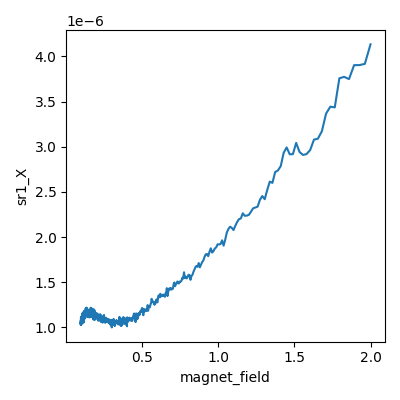

2026-06-20 23:53:55,595 [INFO] Completed in 1h 1m 17s


2026-06-20 23:53:55,596 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260620-QC0426\data\1\data.tsv.gz


DONE run id=1 | T 1.163->1.197 K | field now 2.006 T (left high for electron sweep-down)


In [18]:
import numpy as np, time
from sharpelab_nb import gates

# ---- (n,D) calibration from run 0 (ana cells 11-13) ----
C_TG, C_BG, N_OFF = 1.7027e-3, 2.2024e-3, -0.1445     # F/m^2, F/m^2, 1e12 cm^-2
N_TARGET, D_TARGET = -3.4, 0.0                          # hole side, D=0
Vtg, Vbg = gates.calc_gate_voltages(N_TARGET, D_TARGET, C_TG, C_BG, N_OFF, 0.0)
Vtg, Vbg = float(Vtg), float(Vbg)
assert -6.0 <= Vtg <= 7.0 and -4.5 <= Vbg <= 4.5, f"gate target out of range: Vtg={Vtg}, Vbg={Vbg}"

# ---- field window, uniform in 1/B (Step 2 feasibility) ----
B_LO, B_HI = 0.1, 2.0
F_L = (6.62607e-34 / (4 * 1.602177e-19)) * (abs(N_TARGET) * 1e16)   # Tesla
dinvB = 1.0 / (3.0 * F_L)
N = int(round((1 / B_LO - 1 / B_HI) / dinvB)) + 1
field_vec = field_invB(B_LO, B_HI, N)
assert 0 <= field_vec.min() and field_vec.max() <= 8.0

# ---- preconditions (assumed, not set) ----
assert heater.sample_temperature() < 2.0, f"T high: {heater.sample_temperature()}"
assert k_2410.volt() == 0, f"Si not at 0: {k_2410.volt()}"
T0 = heater.sample_temperature()

# ---- high-|n| metallic bias + position gates/field ----
sr1.amplitude(2.0)                  # 2 V / 100 MOhm = 20 nA
time.sleep(1)
dc205_volt(Vtg); k_bg.volt(Vbg)
magnet.settle_s = 0.2               # field-sweep dwell; lock-in delay carries settling
magnet.field(B_LO)
time.sleep(3)

# ---- sensitivity: autorange Rxx, explicit Hall/current ----
sr0.sensitivity(5e-2)               # 20 nA * 1e6 = 20 mV
sr3.sensitivity(2e-5)               # R_xy(B_hi)=B/(n e) ~ 0.37 kOhm -> 7.3 uV
for s in (sr1, sr2):
    s.autorange(max_changes=5)
time.sleep(2)
I = sr0.X() / meas_config['sr0_gain']
print(f"n={N_TARGET}e12 D=0 -> Vtg={Vtg:.3f} Vbg={Vbg:.3f} | B {B_LO}->{B_HI}T N={N} d(1/B)={dinvB:.5f} F_L={F_L:.1f}T")
print(f"I_drain={I*1e9:+.2f} nA")
for ch in ['sr1', 'sr2', 'sr3', 'sr0']:
    s = globals()[ch]; x = s.X(); se = s.sensitivity()
    print(f"  {ch}: X={x:+.3e}  sens={se:.1e} ({abs(x)/se*100:.0f}% FS)  R={x/I if I else float('nan'):+.1f} ohm")
assert abs(sr1.X()) < 0.9 * sr1.sensitivity() and abs(sr2.X()) < 0.9 * sr2.sensitivity(), "Rxx overloaded at B_lo"

# ---- station + 1/B field sweep ----
meas_config['comments'] = (f"sdh-spot-check HOLE n={N_TARGET}e12 D=0 (Vtg={Vtg:.3f},Vbg={Vbg:.3f}); "
                           f"B {B_LO}-{B_HI}T uniform-1/B N={N} d(1/B)={dinvB:.5f}; F_L={F_L:.1f}T; bias 2V/20nA; "
                           f"src T2/drn B7/sr1 T3-T4/sr2 B4-B5/sr3 T5-B6(Hall)")
meas_config['sample_temperature:'] = T0
meas_config['bias_voltage'] = sr1.amplitude()
for k, ch in [('sr0_sens', 'sr0'), ('sr1_sens', 'sr1'), ('sr2_sens', 'sr2'), ('sr3_sens', 'sr3')]:
    meas_config[k] = globals()[ch].sensitivity()
s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'HOLE n={N_TARGET}e12 D=0; F_L={F_L:.1f}T; uniform-1/B {B_LO}-{B_HI}T N={N} d(1/B)={dinvB:.5f}')
s.fp(sr0.X).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P).fp(k_2400.curr).fp(k_2410.curr)
s.plot(magnet.field, sr1.X)
res = s.sweep(magnet.field, field_vec, delay=2.5)

magnet.settle_s = 3.0               # restore default
T1 = heater.sample_temperature()
print(f"DONE run id={res.id} | T {T0:.3f}->{T1:.3f} K | field now {magnet.field():.3f} T (left high for electron sweep-down)")


## HERA — Step 3 (cont.) · hole SdH at HIGH field, B 2→8 T

Run 1 (B ≤ 2 T) showed onset ~1.3 T and no resolved tones — the device's SdH is high-field (warm T_e ~8 K). **Data-driven extension** (`sdh-spot-check`, the recipe's "extend the range to higher field" trigger): continue the *same* hole point (n=−3.4e12, D=0) **up to the 8 T cap**. Magnet is already at 2 T → sweep **up, no re-traverse** (rig discipline). Combined with run 1 this is a uniform-1/B record over 0.1–8 T.

`field_invB(2.0, 8.0)`, Δ(1/B)≈0.0047 (finer than 1/(3·F_L) for high-B SNR), N≈81, dwell 2.5 s. Sensitivities set explicitly for the 8 T maxima (Rxx MR ~700 Ω → sr1/sr2 2e-5; R_xy(8T) ~1.5 kΩ → sr3 5e-5; current sr0 5e-2), verified <90% FS at the 2 T start (cell aborts otherwise).

**~48 min** (ramp-dominated: 6 T at 0.137 T/min ≈ 44 min). **Checkpoint ~20 min (~B 3.2 T):** SdH oscillations emerging above the MR? channels un-railed? → continue; else run to 8 T anyway (it's the max field — last shot before a resolution-limited call). Leaves magnet at 8 T. If clean tones appear → fixes the fan's field window + side; if not even at 8 T → resolution-limited outcome (Step 7), and the electron side / a lower-T rig become the levers.


hole HIGH-FIELD n=-3.4e12 D=0 Vtg=-1.532 Vbg=-1.184 | B 2.0->8.0T N=81 d(1/B)=0.00469 F_L=35.2T
I=+19.97 nA  field=2.003 T
  sr1: 21% FS  R=+210.4 ohm  sens=2e-05
  sr2: 18% FS  R=+176.6 ohm  sens=2e-05
  sr3: 12% FS  R=-307.8 ohm  sens=5e-05
  sr0: 40% FS  R=-999619.4 ohm  sens=5e-02


2026-06-21 00:00:53,304 [INFO] Starting sweep with ID 2


2026-06-21 00:00:53,305 [INFO] Minimum duration 0h 3m 22s


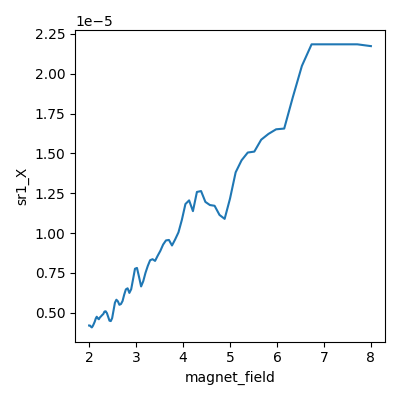

2026-06-21 00:48:22,272 [INFO] Completed in 0h 47m 28s


2026-06-21 00:48:22,273 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260620-QC0426\data\2\data.tsv.gz


DONE run id=2 | T 1.197->1.268 K | field now 8.006 T


In [19]:
import numpy as np, time
from sharpelab_nb import gates

C_TG, C_BG, N_OFF = 1.7027e-3, 2.2024e-3, -0.1445
N_TARGET = -3.4
Vtg, Vbg = gates.calc_gate_voltages(N_TARGET, 0.0, C_TG, C_BG, N_OFF, 0.0)
Vtg, Vbg = float(Vtg), float(Vbg)

# high-field continuation: sweep UP 2->8 T (no re-traverse), uniform-1/B
B_START, B_END = 2.0, 8.0
F_L = (6.62607e-34 / (4 * 1.602177e-19)) * (abs(N_TARGET) * 1e16)
dinvB = 0.00469
N = int(round((1 / B_START - 1 / B_END) / dinvB)) + 1
field_vec = field_invB(B_START, B_END, N)
assert 2.0 <= field_vec.min() and field_vec.max() <= 8.0

# preconditions
assert abs(magnet.field() - 2.0) < 0.06, f"field not ~2T: {magnet.field()}"
assert heater.sample_temperature() < 2.0, f"T high: {heater.sample_temperature()}"
assert k_2410.volt() == 0
dc205_volt(Vtg); k_bg.volt(Vbg); time.sleep(2)
assert abs(dc205.voltage() - Vtg) < 0.02 and abs(k_2400.volt() - Vbg) < 0.02, "gates not at hole point"
T0 = heater.sample_temperature()

# sensitivities sized for 8 T maxima (Rxx MR ~700Ω, R_xy ~1.5kΩ)
sr1.amplitude(2.0)
sr0.sensitivity(5e-2); sr1.sensitivity(2e-5); sr2.sensitivity(2e-5); sr3.sensitivity(5e-5)
magnet.settle_s = 0.2
time.sleep(2)
I = sr0.X() / meas_config['sr0_gain']
print(f"hole HIGH-FIELD n={N_TARGET}e12 D=0 Vtg={Vtg:.3f} Vbg={Vbg:.3f} | B {B_START}->{B_END}T N={N} d(1/B)={dinvB} F_L={F_L:.1f}T")
print(f"I={I*1e9:+.2f} nA  field={magnet.field():.3f} T")
for ch in ['sr1', 'sr2', 'sr3', 'sr0']:
    s = globals()[ch]; x = s.X(); se = s.sensitivity()
    print(f"  {ch}: {abs(x)/se*100:.0f}% FS  R={x/I if I else float('nan'):+.1f} ohm  sens={se:.0e}")
assert abs(sr1.X()) < 0.9 * sr1.sensitivity() and abs(sr2.X()) < 0.9 * sr2.sensitivity(), "Rxx overload at 2T"

meas_config['comments'] = (f"sdh-spot-check HOLE high-field n={N_TARGET}e12 D=0 (Vtg={Vtg:.3f},Vbg={Vbg:.3f}); "
                           f"B {B_START}-{B_END}T uniform-1/B N={N} d(1/B)={dinvB}; F_L={F_L:.1f}T; continues run1(0.1-2T); bias 2V/20nA")
meas_config['sample_temperature:'] = T0
for k, ch in [('sr0_sens', 'sr0'), ('sr1_sens', 'sr1'), ('sr2_sens', 'sr2'), ('sr3_sens', 'sr3')]:
    meas_config[k] = globals()[ch].sensitivity()
s = async_station(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment(f'HOLE high-field n={N_TARGET}e12 D=0; B {B_START}-{B_END}T; continues run1')
s.fp(sr0.X).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P).fp(k_2400.curr).fp(k_2410.curr)
s.plot(magnet.field, sr1.X)
res = s.sweep(magnet.field, field_vec, delay=2.5)
magnet.settle_s = 3.0
T1 = heater.sample_temperature()
print(f"DONE run id={res.id} | T {T0:.3f}->{T1:.3f} K | field now {magnet.field():.3f} T")


## HERA — Step 4 · Landau fan (per-column SdH-FFT), HOLE side, D = 0

`landau-fan-vti`. The spot checks (runs 1+2) resolved **two robust tones at n=−3.4e12: ~20 T and ~35 T (≈F_L)** — not a clean single-tone ABC. The fan tracks **F(n) across density** to settle the Luttinger partition (Σf(n) = F_L(n) is algebraic — a one-density coincidence won't hold) and read each Rxx region separately.

**Cost-floored design (one fan, every lever at its floor):**
- **B_lo = 1.4 T** — the measured onset. `sdh_onset` did not converge on the gradual-onset high-field data (returns nan); 1.4 T is the visual onset from ΔRxx(1/B) (oscillations emerge ~1.3–1.5 T). Stated caveat.
- **n_max = 3.5e12** — clamped to the Onsager-overlay validity (not extended for the low-n edge).
- **B_max = 8 T** — magnet is already there → sweep **down** to 1.4 T (no re-traverse). uniform-1/B (`field_invB`), Δ(1/B)=1/(3·F_L,max)=0.0092 → **N_B=64**, Nyquist 54 T > F_L_max 36 T.
- **N_n = 31** — ray-Nyquist floor at B_lo (LL group Δn=0.126e12, ≥2 pts). n = −3.5→−1.5e12 at D=0.
- **Fixed sens 1e-4** (sr1/sr2) — sized for the worst corner (low-|n|×high-B ≈ 2.3 kΩ → 45% FS; clipping would corrupt a whole column's FFT). sr3 2e-4, sr0 5e-2. Bias 2 V/20 nA, dwell **1.8 s (6τ — n-axis carries the signal)**.

**~1.8 h** (≈59 min dwell + ≈48 min ramp 8→1.4 T). **Checkpoint ~15 min (first rows at 8 T = the worst dynamic-range corner):** sr1/sr2 un-railed at low-|n|×8 T, leakage <1 nA, rate sane → continue; else interrupt & resize. Fan ends at 1.4 T. FFT each n-column → F(n) per channel vs F_L(n).


FAN D=0 hole n[-3.5,-1.5]e12 x31 | B 8.0->1.4T x65 d(1/B)=0.00921 F_L_max=36.2T | dwell 1.8s
  sr1: 23% FS  R=+1166 ohm  sens=1e-04
  sr2: 17% FS  R=+889 ohm  sens=1e-04
  sr3: 14% FS  R=-1408 ohm  sens=2e-04
  sr0: 39% FS  R=-1000483 ohm  sens=5e-02


2026-06-21 00:56:48,675 [INFO] Starting multimegasweep with ID 3


2026-06-21 00:56:48,677 [INFO] Minimum duration 1h 1m 32s


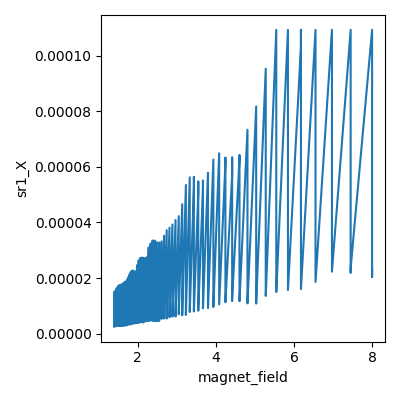

2026-06-21 02:56:41,301 [INFO] Completed in 1h 59m 52s


2026-06-21 02:56:41,302 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260620-QC0426\data\3\data.tsv.gz


DONE run id=3 | T 1.264->1.184 K | field now 1.403 T


In [20]:
import numpy as np, time
from sharpelab_nb import gates

C_TG, C_BG, N_OFF = 1.7027e-3, 2.2024e-3, -0.1445
h, e = 6.62607e-34, 1.602177e-19
B_MAX, B_LO = 8.0, 1.4
n_hi, n_lo = -3.5, -1.5                      # 1e12 cm^-2, hole, D=0

F_L_max = (h / (4 * e)) * (abs(n_hi) * 1e16)
dinvB = 1.0 / (3.0 * F_L_max)
N_B = int(np.ceil((1 / B_LO - 1 / B_MAX) / dinvB)) + 1
dn_ray = 4 * (e * B_LO / h) / 1e16
N_n = int(np.ceil(abs(n_lo - n_hi) / (dn_ray / 2))) + 1
B_vec = field_invB(B_MAX, B_LO, N_B)
ns = np.linspace(n_hi, n_lo, N_n)
Vtgs, Vbgs = gates.calc_gate_voltages(ns, ns * 0, C_TG, C_BG, N_OFF, 0.0)
Vtgs, Vbgs = sanitize_tg_bg(np.asarray(Vtgs, float), np.asarray(Vbgs, float), tg_lims, bg_lims)
assert len(Vtgs) == len(ns), "n-line clipped by validators — unexpected at D=0"
assert B_vec.max() <= 8.0 and B_vec.min() >= B_LO and np.all(np.diff(B_vec) < 0), "B_vec bad"

# preconditions
assert abs(magnet.field() - 8.0) < 0.1, f"field not ~8T: {magnet.field()}"
assert heater.sample_temperature() < 2.0, f"T high: {heater.sample_temperature()}"
assert k_2410.volt() == 0
T0 = heater.sample_temperature()

# bias + fixed sensitivity (dynamic range: worst corner low-|n| x high-B)
sr1.amplitude(2.0)
sr0.sensitivity(5e-2); sr1.sensitivity(1e-4); sr2.sensitivity(1e-4); sr3.sensitivity(2e-4)
dc205_volt(Vtgs[0]); k_bg.volt(Vbgs[0]); time.sleep(2)     # position at first fast point (field already 8T)
print(f"FAN D=0 hole n[{n_hi},{n_lo}]e12 x{len(ns)} | B {B_MAX}->{B_LO}T x{N_B} d(1/B)={dinvB:.5f} F_L_max={F_L_max:.1f}T | dwell 1.8s")
I = sr0.X() / meas_config['sr0_gain']
for ch in ['sr1', 'sr2', 'sr3', 'sr0']:
    s = globals()[ch]; x = s.X(); se = s.sensitivity()
    print(f"  {ch}: {abs(x)/se*100:.0f}% FS  R={x/I if I else float('nan'):+.0f} ohm  sens={se:.0e}")
assert abs(sr1.X()) < 0.9 * sr1.sensitivity() and abs(sr2.X()) < 0.9 * sr2.sensitivity(), "Rxx overload at worst corner (low-|n|,8T)"

meas_config['comments'] = (f"landau-fan-vti HOLE D=0 n={n_hi}..{n_lo}e12 ({len(ns)}pts) x B {B_MAX}->{B_LO}T uniform-1/B "
                           f"({N_B}pts d1/B={dinvB:.5f}); per-column SdH-FFT; F_L_max={F_L_max:.1f}T; bias 2V/20nA; "
                           f"src T2/drn B7/sr1 T3-T4/sr2 B4-B5/sr3 T5-B6(Hall)")
meas_config['sample_temperature:'] = T0
for k, ch in [('sr0_sens', 'sr0'), ('sr1_sens', 'sr1'), ('sr2_sens', 'sr2'), ('sr3_sens', 'sr3')]:
    meas_config[k] = globals()[ch].sensitivity()
s = async_station(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment(f'D=0 hole; n={n_hi} to {n_lo}e12; B={B_MAX} to {B_LO}T; per-column SdH-FFT fan')
s.fp(sr0.X).fp(sr1.X).fp(sr1.P).fp(sr2.X).fp(sr2.P).fp(sr3.X).fp(sr3.P).fp(k_2400.curr).fp(k_2410.curr)
s.plot(magnet.field, sr1.X)
magnet.settle_s = 1.0
res = s.multimegasweep([magnet.field], [B_vec], [dc205_volt, k_bg.volt], [Vtgs, Vbgs], slow_delay=1.0, fast_delay=1.8)
magnet.settle_s = 3.0
T1 = heater.sample_temperature()
print(f"DONE run id={res.id} | T {T0:.3f}->{T1:.3f} K | field now {magnet.field():.3f} T")


In [21]:
# End-of-goal park: field -> 0, gates -> 0 (safe idle). Primary goal met (ABA call).
import time
magnet.settle_s = 3.0
print("parking field", round(magnet.field(), 3), "T -> 0 ...")
magnet.field(0.0)
dc205_volt(0.0); k_bg.volt(0.0)
print(f"parked: B={magnet.field():.4f}T TG={dc205.voltage():.3f}V BG={k_2400.volt():.3f}V "
      f"Si={k_2410.volt():.3f}V T={heater.sample_temperature():.3f}K")


parking field 1.403 T -> 0 ...


parked: B=-0.0008T TG=0.000V BG=0.000V Si=0.000V T=1.161K
